Data Sources

In [1]:
import pandas as pd

# Load raw operations (Excel file - use read_excel, not read_csv)
operations = pd.read_excel('data/operations.xlsx')
print("Operations shape:", operations.shape)
print("\nFirst 5 rows of raw operations:")
print(operations.head())

Operations shape: (375267, 5)

First 5 rows of raw operations:
              transaction_date  authorized_amount  merchant_code  \
0  Thursday, December 12, 2024              200.0         6011.0   
1  Thursday, December 12, 2024              200.0         6011.0   
2  Thursday, December 12, 2024              200.0         6011.0   
3     Monday, December 2, 2024              200.0         6011.0   
4     Monday, December 2, 2024              200.0         6011.0   

   account_number               merchant_key  
0      1007184714  GAB BH KHEIREDDINE P|6011  
1      1007259354  GAB BH KHEIREDDINE P|6011  
2      1007814466  GAB BH KHEIREDDINE P|6011  
3      1007306359  GAB BH KHEIREDDINE P|6011  
4      1007942000  GAB BH KHEIREDDINE P|6011  


In [2]:
# Load raw merchants
merchants = pd.read_csv('data/merchant.csv', delimiter=';', encoding='utf-8')

# Remove unnamed columns (columns that contain 'Unnamed' in their name)
merchants = merchants.loc[:, ~merchants.columns.str.contains('Unnamed', case=False)]

print("Merchants shape:", merchants.shape)
print("\nFirst 5 rows of raw merchants (after removing unnamed columns):")
print(merchants.head())

Merchants shape: (33852, 3)

First 5 rows of raw merchants (after removing unnamed columns):
   merchant_code         merchant_name    Category
0          742.0  ALIF DISTRIBUTION     Healthcare
1          742.0  C VETERINAIRE BOURAO  Healthcare
2          742.0  CLINIQUE VETERINAIRE  Healthcare
3          742.0  DR AHLEM BELKADHI     Healthcare
4          742.0  DR MAWAKED HANNACHI   Healthcare


In [3]:
# Load raw clients (if you have it, or show generated clients later)
clients = pd.read_csv('data/clients.csv', delimiter=';', encoding='utf-8')
print("Clients shape:", clients.shape)
print("\nFirst 5 rows of raw clients:")
print(clients.head())

Clients shape: (9249, 1)

First 5 rows of raw clients:
  client_id,account_number,full_name,date_of_birth,marital_status,gender,job_position,residence_location,age
0  C004254,1007590439,Hela Abdelli,1985-01-18,Mar...                                                        
1  C001571,1007181351,Raja Chihi,1981-10-16,Marié...                                                        
2  C002556,1007341237,Imed Ghribi,1993-10-22,Mari...                                                        
3  C005236,1007215322,Haythem U. Sfar,1992-04-18,...                                                        
4  C001215,1007242230,Mohamed Bouguerra,1990-10-2...                                                        


Data Types and Unique Values

In [5]:
print("="*50)
print("DATA TYPES")
print("="*50)

print("\nOPERATIONS data types:")
ops_dtypes = operations.dtypes
if 'merchant_key' in ops_dtypes:
    ops_dtypes = ops_dtypes.drop('merchant_key')
print(ops_dtypes)

print("\nMERCHANTS data types:")
print(merchants.dtypes)

print("\nCLIENTS data types:")
print(clients.dtypes)

DATA TYPES

OPERATIONS data types:
transaction_date      object
authorized_amount    float64
merchant_code        float64
account_number         int64
dtype: object

MERCHANTS data types:
merchant_code    float64
merchant_name     object
Category          object
dtype: object

CLIENTS data types:
client_id,account_number,full_name,date_of_birth,marital_status,gender,job_position,residence_location,age    object
dtype: object


In [41]:
# Show unique values in categorical columns
categorical_cols = operations.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"{col}: {operations[col].nunique()} unique values")
    print(operations[col].unique()[:5])  # first 5 unique values
    print("---")

transaction_date: 202 unique values
['Thursday, December 12, 2024' 'Monday, December 2, 2024'
 'Wednesday, December 11, 2024' 'Friday, December 6, 2024'
 'Sunday, December 8, 2024']
---
merchant_key: 9774 unique values
['GAB BH KHEIREDDINE P|6011' 'BH EL AOUINA        |6011'
 'BH ALAIN SAVARY     |6011' 'BH EL GHAZELA       |6011'
 "BH CENTRE D'AFFAIRES|6011"]
---


Missing Values Summary

In [42]:
print("="*50)
print("MISSING VALUES SUMMARY")
print("="*50)

def show_missing(df, name):
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
    missing_df = missing_df[missing_df['Missing Count'] > 0]
    
    print(f"\n{name}:")
    if not missing_df.empty:
        print(missing_df.to_string())
    else:
        print("  No missing values found.")

show_missing(operations, "OPERATIONS")
show_missing(merchants, "MERCHANTS")
show_missing(clients, "CLIENTS")

MISSING VALUES SUMMARY

OPERATIONS:
                   Missing Count  Missing %
transaction_date               7   0.001865
authorized_amount            100   0.026648
merchant_code                  7   0.001865
merchant_key                   7   0.001865

MERCHANTS:
               Missing Count  Missing %
merchant_code          24309  71.809642
merchant_name          24308  71.806688
Category               24308  71.806688

CLIENTS:
  No missing values found.


Remove Duplicates (All Datasets)

In [43]:
print("="*50)
print("DUPLICATE ROWS COUNT")
print("="*50)

# Operations
ops_duplicates = operations.duplicated().sum()
print(f"\nOPERATIONS:")
print(f"  Total rows: {len(operations)}")
print(f"  Duplicate rows: {ops_duplicates}")
print(f"  Unique rows: {len(operations) - ops_duplicates}")

# Merchants
mer_duplicates = merchants.duplicated().sum()
print(f"\nMERCHANTS:")
print(f"  Total rows: {len(merchants)}")
print(f"  Duplicate rows: {mer_duplicates}")
print(f"  Unique rows: {len(merchants) - mer_duplicates}")

# Clients
cli_duplicates = clients.duplicated().sum()
print(f"\nCLIENTS:")
print(f"  Total rows: {len(clients)}")
print(f"  Duplicate rows: {cli_duplicates}")
print(f"  Unique rows: {len(clients) - cli_duplicates}")

DUPLICATE ROWS COUNT

OPERATIONS:
  Total rows: 375267
  Duplicate rows: 29607
  Unique rows: 345660

MERCHANTS:
  Total rows: 33852
  Duplicate rows: 24306
  Unique rows: 9546

CLIENTS:
  Total rows: 9249
  Duplicate rows: 0
  Unique rows: 9249


In [44]:
import pandas as pd

# Load clients correctly (assuming it's a CSV with comma delimiter)
# Try different options until it works
print("="*50)
print("RELOADING CLIENTS DATA CORRECTLY")
print("="*50)

# Option 1: Try loading normally
try:
    clients = pd.read_csv('data/clients.csv', delimiter=',', encoding='utf-8')
    print("✅ Loaded with comma delimiter")
except:
    # Option 2: Try with semicolon
    try:
        clients = pd.read_csv('data/clients.csv', delimiter=';', encoding='utf-8')
        print("✅ Loaded with semicolon delimiter")
    except:
        # Option 3: No delimiter specified
        clients = pd.read_csv('data/clients.csv', encoding='utf-8')
        print("✅ Loaded with default delimiter")

print(f"Shape: {clients.shape}")
print(f"Columns: {list(clients.columns)}")
print("\nFirst 5 rows:")
print(clients.head())

RELOADING CLIENTS DATA CORRECTLY
✅ Loaded with comma delimiter
Shape: (9249, 9)
Columns: ['client_id', 'account_number', 'full_name', 'date_of_birth', 'marital_status', 'gender', 'job_position', 'residence_location', 'age']

First 5 rows:
  client_id  account_number          full_name date_of_birth marital_status  \
0   C004254      1007590439     Chiraz Abdelli    1985-01-18       Marié(e)   
1   C001571      1007181351         Raja Chihi    1981-10-16       Marié(e)   
2   C002556      1007341237        Imed Ghribi    1993-10-22       Marié(e)   
3   C005236      1007215322    Haythem U. Sfar    1992-04-18     Divorcé(e)   
4   C001215      1007242230  Mohamed Bouguerra    1990-10-28       Marié(e)   

  gender                     job_position  residence_location  age  
0      F                       Pharmacien      Msaken, Sousse   41  
1      F              Professeur de Lycée  Monastir, Monastir   44  
2      M            Professeur des Écoles     Mateur, Bizerte   32  
3      M  

In [45]:
print("="*50)
print("CLEANING CLIENTS DATA")
print("="*50)

# Clean column names (remove extra spaces)
clients.columns = clients.columns.str.strip()

# Clean string columns (remove quotes and extra spaces)
for col in clients.select_dtypes(include=['object']).columns:
    clients[col] = clients[col].astype(str).str.strip().str.strip('"').str.strip("'")

# Convert age to numeric if it exists
if 'age' in clients.columns:
    clients['age'] = pd.to_numeric(clients['age'], errors='coerce')
    print(f"Age column converted to numeric")
    print(f"Age range: {clients['age'].min()} to {clients['age'].max()}")

# Convert date_of_birth to datetime if it exists
if 'date_of_birth' in clients.columns:
    clients['date_of_birth'] = pd.to_datetime(clients['date_of_birth'], errors='coerce')

print("\n✅ Clients data cleaned")
print(f"Shape: {clients.shape}")
print(f"Columns: {list(clients.columns)}")
print("\nFirst 5 rows:")
print(clients.head())

CLEANING CLIENTS DATA
Age column converted to numeric
Age range: 18 to 90

✅ Clients data cleaned
Shape: (9249, 9)
Columns: ['client_id', 'account_number', 'full_name', 'date_of_birth', 'marital_status', 'gender', 'job_position', 'residence_location', 'age']

First 5 rows:
  client_id  account_number          full_name date_of_birth marital_status  \
0   C004254      1007590439     Chiraz Abdelli    1985-01-18       Marié(e)   
1   C001571      1007181351         Raja Chihi    1981-10-16       Marié(e)   
2   C002556      1007341237        Imed Ghribi    1993-10-22       Marié(e)   
3   C005236      1007215322    Haythem U. Sfar    1992-04-18     Divorcé(e)   
4   C001215      1007242230  Mohamed Bouguerra    1990-10-28       Marié(e)   

  gender                     job_position  residence_location  age  
0      F                       Pharmacien      Msaken, Sousse   41  
1      F              Professeur de Lycée  Monastir, Monastir   44  
2      M            Professeur des Écoles   

In [46]:
print("="*50)
print("PLACEHOLDER CLIENTS DETECTION")
print("="*50)

# Find the name column
name_col = None
for col in ['full_name', 'name', 'client_name', 'Full_Name']:
    if col in clients.columns:
        name_col = col
        break

if name_col:
    print(f"Name column found: '{name_col}'")
    
    # Placeholder patterns
    placeholder_pattern = r'Client C\d+|Client C_\d+|Client Orphelin|^C\d{6}$'
    placeholders = clients[clients[name_col].astype(str).str.contains(placeholder_pattern, case=False, na=False)]
    
    print(f"\nPlaceholder clients found: {len(placeholders)}")
    
    if len(placeholders) > 0:
        print(f"Percentage of total: {len(placeholders)/len(clients)*100:.2f}%")
        print("\nSample of placeholder clients (first 5):")
        print(placeholders[['client_id', name_col]].head())
    else:
        print("  No placeholder clients found.")
else:
    print("❌ Name column not found. Available columns:")
    print(list(clients.columns))

PLACEHOLDER CLIENTS DETECTION
Name column found: 'full_name'

Placeholder clients found: 127
Percentage of total: 1.37%

Sample of placeholder clients (first 5):
    client_id       full_name
95    C003408  Client C003408
207   C001410  Client C001410
327   C001410  Client C001410
392   C002366  Client C002366
631   C004441  Client C004441


In [47]:
print("="*50)
print("DATA TYPES OF CLIENTS TABLE")
print("="*50)

print(clients.dtypes)

DATA TYPES OF CLIENTS TABLE
client_id                     object
account_number                 int64
full_name                     object
date_of_birth         datetime64[ns]
marital_status                object
gender                        object
job_position                  object
residence_location            object
age                            int64
dtype: object


In [48]:
print("="*50)
print("PLACEHOLDER JOB POSITIONS DETECTION")
print("="*50)

# Find job column (try common names)
job_col = None
for col in ['job_position', 'job', 'profession', 'Job_Position', 'Job']:
    if col in clients.columns:
        job_col = col
        break

if job_col:
    print(f"Job column found: '{job_col}'")
    
    # Define placeholder/generic job patterns
    job_placeholders = [
        'professionnel',
        'profession',
        'unknown',
        'n/a',
        'nan',
        'autre',
        'indéfini',
        'undefined',
        'employé'  # too generic
    ]
    
    # Also detect generic one-word jobs that are placeholders
    placeholder_mask = clients[job_col].astype(str).str.lower().isin(job_placeholders)
    
    # Also detect if job is too short (like '--' or '?')
    short_mask = clients[job_col].astype(str).str.len() < 3
    
    placeholders = clients[placeholder_mask | short_mask]
    
    print(f"\nPlaceholder/generic job positions found: {len(placeholders)}")
    
    if len(placeholders) > 0:
        print(f"Percentage of total: {len(placeholders)/len(clients)*100:.2f}%")
        print("\nUnique placeholder job values:")
        print(clients.loc[placeholder_mask | short_mask, job_col].value_counts().head(10))
        
        print("\nSample of placeholder job entries (first 5):")
        display_cols = ['client_id', job_col]
        if 'full_name' in clients.columns:
            display_cols.insert(1, 'full_name')
        print(placeholders[display_cols].head())
    else:
        print("  No placeholder job positions found.")
else:
    print("❌ Job column not found. Available columns:")
    print(list(clients.columns))

PLACEHOLDER JOB POSITIONS DETECTION
Job column found: 'job_position'

Placeholder/generic job positions found: 127
Percentage of total: 1.37%

Unique placeholder job values:
job_position
Professionnel    127
Name: count, dtype: int64

Sample of placeholder job entries (first 5):
    client_id       full_name   job_position
95    C003408  Client C003408  Professionnel
207   C001410  Client C001410  Professionnel
327   C001410  Client C001410  Professionnel
392   C002366  Client C002366  Professionnel
631   C004441  Client C004441  Professionnel


In [49]:
print("="*50)
print("REMOVING DUPLICATES")
print("="*50)

# Operations
before_ops = len(operations)
operations = operations.drop_duplicates()
after_ops = len(operations)
print(f"\nOPERATIONS:")
print(f"  Before: {before_ops} rows")
print(f"  After: {after_ops} rows")
print(f"  Removed: {before_ops - after_ops} duplicates")

# Merchants
before_mer = len(merchants)
merchants = merchants.drop_duplicates()
after_mer = len(merchants)
print(f"\nMERCHANTS:")
print(f"  Before: {before_mer} rows")
print(f"  After: {after_mer} rows")
print(f"  Removed: {before_mer - after_mer} duplicates")

# Clients
before_cli = len(clients)
clients = clients.drop_duplicates()
after_cli = len(clients)
print(f"\nCLIENTS:")
print(f"  Before: {before_cli} rows")
print(f"  After: {after_cli} rows")
print(f"  Removed: {before_cli - after_cli} duplicates")

REMOVING DUPLICATES

OPERATIONS:
  Before: 375267 rows
  After: 345660 rows
  Removed: 29607 duplicates

MERCHANTS:
  Before: 33852 rows
  After: 9546 rows
  Removed: 24306 duplicates

CLIENTS:
  Before: 9249 rows
  After: 9249 rows
  Removed: 0 duplicates


In [50]:
import pandas as pd

def impute_missing_clean(df, name):
    """Impute missing values: median for numeric, mode for categorical.
       Returns cleaned df and a summary DataFrame."""
    print(f"\n{'='*60}")
    print(f"{name} – MISSING VALUE IMPUTATION")
    print('='*60)
    
    # Check missing before
    missing_before = df.isnull().sum()
    missing_before = missing_before[missing_before > 0]
    
    if missing_before.empty:
        print(f"✅ {name} already has no missing values.")
        return df, pd.DataFrame()
    
    print("\nMissing values BEFORE imputation:")
    print(missing_before.to_string())
    
    # Impute column by column
    imputed_info = []
    for col in df.columns:
        if df[col].isnull().any():
            if df[col].dtype in ['float64', 'int64']:
                median_val = df[col].median()
                df[col] = df[col].fillna(median_val)
                imputed_info.append([col, 'median', f"{median_val:.2f}"])
            else:
                mode_val = df[col].mode()
                if not mode_val.empty:
                    fill_val = mode_val[0]
                else:
                    fill_val = 'Unknown'
                df[col] = df[col].fillna(fill_val)
                imputed_info.append([col, 'mode', str(fill_val)])
    
    # Check missing after
    missing_after = df.isnull().sum()
    missing_after = missing_after[missing_after > 0]
    
    print("\nMissing values AFTER imputation:")
    if missing_after.empty:
        print("  ✅ No missing values remain.")
    else:
        print(missing_after.to_string())
    
    # Summary of imputations
    if imputed_info:
        print("\n📊 Imputation summary:")
        imp_df = pd.DataFrame(imputed_info, columns=['Column', 'Method', 'Value used'])
        print(imp_df.to_string(index=False))
    
    return df, imp_df

# Apply to each dataset
operations, imp_ops = impute_missing_clean(operations, "Operations")
merchants, imp_mer = impute_missing_clean(merchants, "Merchants")
clients, imp_cli = impute_missing_clean(clients, "Clients")

# ============================================================
# FINAL VERIFICATION (clean table)
# ============================================================
print("\n" + "="*60)
print("FINAL VERIFICATION – ALL DATASETS")
print("="*60)

final_check = []
for name, df in [('Operations', operations), ('Merchants', merchants), ('Clients', clients)]:
    missing = df.isnull().sum().sum()
    status = "✅ Clean" if missing == 0 else f"⚠️ {missing} missing"
    final_check.append([name, df.shape[0], df.shape[1], status])

final_df = pd.DataFrame(final_check, columns=['Dataset', 'Rows', 'Columns', 'Missing Status'])
print(final_df.to_string(index=False))


Operations – MISSING VALUE IMPUTATION

Missing values BEFORE imputation:
transaction_date      1
authorized_amount    88
merchant_code         1
merchant_key          1

Missing values AFTER imputation:
  ✅ No missing values remain.

📊 Imputation summary:
           Column Method                Value used
 transaction_date   mode Thursday, January 2, 2025
authorized_amount median                    109.41
    merchant_code median                   6011.00
     merchant_key   mode                LOYER|6513

Merchants – MISSING VALUE IMPUTATION

Missing values BEFORE imputation:
merchant_code    3
merchant_name    2
Category         2

Missing values AFTER imputation:
  ✅ No missing values remain.

📊 Imputation summary:
       Column Method           Value used
merchant_code median              5912.00
merchant_name   mode LAB ANALYSES MEDICAL
     Category   mode     Banking Services

Clients – MISSING VALUE IMPUTATION
✅ Clients already has no missing values.

FINAL VERIFICATION – ALL 

Remove Negative Amounts (Operations)

In [51]:
print("="*50)
print("REMOVING NEGATIVE AMOUNTS (OPERATIONS)")
print("="*50)

# Identify the amount column (adjust name if different)
amount_col = None
for col in operations.columns:
    if 'amount' in col.lower() or 'montant' in col.lower() or 'authorized' in col.lower():
        amount_col = col
        break

if amount_col:
    neg_count = (operations[amount_col] < 0).sum()
    print(f"Amount column used: {amount_col}")
    print(f"Negative amounts found: {neg_count}")
    
    operations = operations[operations[amount_col] >= 0]
    print(f"After removal: {len(operations)} rows")
else:
    print("No amount column found. Please check column names:")
    print(list(operations.columns))

REMOVING NEGATIVE AMOUNTS (OPERATIONS)
Amount column used: authorized_amount
Negative amounts found: 0
After removal: 345660 rows


In [52]:
import pandas as pd

# Load clients (adjust path and delimiter as needed)
# If you have a properly loaded clients DataFrame already, skip loading
try:
    clients = pd.read_csv('data/clients.csv', delimiter=',', encoding='utf-8')
except:
    # Manual parse if needed
    with open('data/clients.csv', 'r', encoding='utf-8') as f:
        lines = f.readlines()
    headers = lines[0].strip().split(',')
    data = [line.strip().split(',') for line in lines[1:]]
    clients = pd.DataFrame(data, columns=headers)

# Clean string columns (remove quotes and spaces)
for col in clients.columns:
    clients[col] = clients[col].astype(str).str.strip().str.strip('"').str.strip("'")

# Find age column
age_col = None
for col in clients.columns:
    if 'age' in col.lower():
        age_col = col
        break

if age_col:
    # Convert to numeric
    clients[age_col] = pd.to_numeric(clients[age_col], errors='coerce')
    
    # Count ages > 120
    above_120 = clients[clients[age_col] > 120]
    count_above_120 = len(above_120)
    
    print(f"Age column: {age_col}")
    print(f"Total clients: {len(clients)}")
    print(f"Clients with age > 120: {count_above_120}")
    
    if count_above_120 > 0:
        print(f"Percentage: {count_above_120/len(clients)*100:.4f}%")
        print("\nSample of clients with age > 120 (first 10):")
        display_cols = ['client_id', age_col]
        if 'full_name' in clients.columns:
            display_cols.insert(1, 'full_name')
        print(above_120[display_cols].head(10))
        
        # Show min and max
        print(f"\nMinimum age among those >120: {above_120[age_col].min()}")
        print(f"Maximum age: {above_120[age_col].max()}")
    else:
        print("No clients with age > 120 found.")
else:
    print("Age column not found. Columns:", list(clients.columns))

Age column: age
Total clients: 9249
Clients with age > 120: 0
No clients with age > 120 found.


Outlier Detection (IQR) for Operations

In [53]:
print("="*50)
print("OUTLIER DETECTION (IQR METHOD) - OPERATIONS")
print("="*50)

if amount_col:
    Q1 = operations[amount_col].quantile(0.25)
    Q3 = operations[amount_col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = operations[(operations[amount_col] < lower_bound) | (operations[amount_col] > upper_bound)]
    
    print(f"Amount column: {amount_col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)} ({len(outliers)/len(operations)*100:.2f}%)")

OUTLIER DETECTION (IQR METHOD) - OPERATIONS
Amount column: authorized_amount
Q1: 50.00
Q3: 400.00
IQR: 350.00
Lower bound: -475.00
Upper bound: 925.00
Number of outliers: 5438 (1.57%)


Outlier Capping (99.9th Percentile) - Operations

In [54]:
print("="*50)
print("OUTLIER CAPPING (99.9th PERCENTILE) - OPERATIONS")
print("="*50)

if amount_col:
    cap_value = operations[amount_col].quantile(0.999)
    capped_count = (operations[amount_col] > cap_value).sum()
    
    print(f"99.9th percentile value: {cap_value:.2f}")
    print(f"Rows above cap: {capped_count}")
    
    # Create capped column (keep original for audit)
    operations[f'{amount_col}_capped'] = operations[amount_col].clip(upper=cap_value)
    
    print(f"\nOriginal max: {operations[amount_col].max():.2f}")
    print(f"Capped max: {operations[f'{amount_col}_capped'].max():.2f}")
    print(f"\nFirst 10 rows (original vs capped):")
    print(operations[[amount_col, f'{amount_col}_capped']].head(10))

OUTLIER CAPPING (99.9th PERCENTILE) - OPERATIONS
99.9th percentile value: 1500.00
Rows above cap: 124

Original max: 9333.00
Capped max: 1500.00

First 10 rows (original vs capped):
   authorized_amount  authorized_amount_capped
0              200.0                     200.0
1              200.0                     200.0
2              200.0                     200.0
3              200.0                     200.0
4              200.0                     200.0
5              200.0                     200.0
6              200.0                     200.0
7              200.0                     200.0
8              200.0                     200.0
9              200.0                     200.0


Account Masking Example

In [55]:
print("="*50)
print("ACCOUNT MASKING EXAMPLE")
print("="*50)

def mask_account(account_num):
    account_str = str(account_num)
    if len(account_str) <= 4:
        return account_str
    prefix = account_str[:4]
    suffix = account_str[4:]
    # Replace digits with '*', keep non-digits
    masked_suffix = ''.join(['*' if c.isdigit() else c for c in suffix])
    return prefix + masked_suffix

# Find account column
account_col = None
for col in operations.columns:
    if 'account' in col.lower() or 'cpte' in col.lower() or 'compte' in col.lower():
        account_col = col
        break

if account_col:
    sample_accounts = operations[account_col].dropna().unique()[:10]
    print(f"Account column used: {account_col}")
    print("\nOriginal -> Masked")
    for acc in sample_accounts:
        print(f"{acc} -> {mask_account(acc)}")
else:
    print("No account column found.")

ACCOUNT MASKING EXAMPLE
Account column used: account_number

Original -> Masked
1007184714 -> 1007******
1007259354 -> 1007******
1007814466 -> 1007******
1007306359 -> 1007******
1007942000 -> 1007******
1007269931 -> 1007******
1007461554 -> 1007******
1007803270 -> 1007******
1007756732 -> 1007******
1007071078 -> 1007******


Standardise String Formats

In [56]:
print("="*50)
print("STANDARDISING STRING FORMATS")
print("="*50)

# For Merchants - standardise category and merchant name
if 'Category' in merchants.columns:
    merchants['Category'] = merchants['Category'].str.upper().str.strip()
    print("Merchants: Category converted to uppercase")

if 'merchant_name' in merchants.columns:
    merchants['merchant_name'] = merchants['merchant_name'].str.title().str.strip()
    print("Merchants: merchant_name converted to title case")

# For Clients - standardise gender and marital status
if 'gender' in clients.columns:
    clients['gender'] = clients['gender'].str.upper().str.strip()
    print("Clients: gender converted to uppercase")

if 'marital_status' in clients.columns:
    clients['marital_status'] = clients['marital_status'].str.capitalize().str.strip()
    print("Clients: marital_status converted to capitalize")

print("\nSample after standardisation:")
print("\nMerchants sample:")
print(merchants.head(3))
print("\nClients sample:")
print(clients.head(3))

STANDARDISING STRING FORMATS
Merchants: Category converted to uppercase
Merchants: merchant_name converted to title case
Clients: gender converted to uppercase
Clients: marital_status converted to capitalize

Sample after standardisation:

Merchants sample:
   merchant_code         merchant_name    Category
0          742.0     Alif Distribution  HEALTHCARE
1          742.0  C Veterinaire Bourao  HEALTHCARE
2          742.0  Clinique Veterinaire  HEALTHCARE

Clients sample:
  client_id account_number       full_name date_of_birth marital_status  \
0   C004254     1007590439  Chiraz Abdelli    1985-01-18       Marié(e)   
1   C001571     1007181351      Raja Chihi    1981-10-16       Marié(e)   
2   C002556     1007341237     Imed Ghribi    1993-10-22       Marié(e)   

  gender           job_position  residence_location  age  
0      F             Pharmacien      Msaken, Sousse   41  
1      F    Professeur de Lycée  Monastir, Monastir   44  
2      M  Professeur des Écoles     Mateur,

Final Cleaned Files Summary

In [57]:
print("="*50)
print("FINAL CLEANED DATASETS SUMMARY")
print("="*50)

print(f"\nOPERATIONS:")
print(f"  Shape: {operations.shape}")
print(f"  Columns: {list(operations.columns)}")

print(f"\nMERCHANTS:")
print(f"  Shape: {merchants.shape}")
print(f"  Columns: {list(merchants.columns)}")

print(f"\nCLIENTS:")
print(f"  Shape: {clients.shape}")
print(f"  Columns: {list(clients.columns)}")

FINAL CLEANED DATASETS SUMMARY

OPERATIONS:
  Shape: (345660, 6)
  Columns: ['transaction_date', 'authorized_amount', 'merchant_code', 'account_number', 'merchant_key', 'authorized_amount_capped']

MERCHANTS:
  Shape: (9546, 3)
  Columns: ['merchant_code', 'merchant_name', 'Category']

CLIENTS:
  Shape: (9249, 9)
  Columns: ['client_id', 'account_number', 'full_name', 'date_of_birth', 'marital_status', 'gender', 'job_position', 'residence_location', 'age']


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for graphs
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# Load raw data
operations = pd.read_excel('data/operations.xlsx')
merchants = pd.read_csv('data/merchant.csv', delimiter=';', encoding='utf-8')
clients = pd.read_csv('data/clients.csv', delimiter=';', encoding='utf-8')

# IMPORTANT: Save copies of raw data BEFORE any cleaning
operations_raw = operations.copy()
merchants_raw = merchants.copy()
clients_raw = clients.copy()

print("✅ Raw data loaded and saved as copies (operations_raw, merchants_raw, clients_raw)")
print(f"Operations: {len(operations)} rows")
print(f"Merchants: {len(merchants)} rows")
print(f"Clients: {len(clients)} rows")

✅ Raw data loaded and saved as copies (operations_raw, merchants_raw, clients_raw)
Operations: 375267 rows
Merchants: 33852 rows
Clients: 9249 rows


In [59]:
print("="*50)
print("REMOVING UNNAMED COLUMNS (MERCHANTS)")
print("="*50)

print(f"Before: {merchants.shape[1]} columns")
merchants = merchants.loc[:, ~merchants.columns.str.contains('Unnamed', case=False)]
print(f"After: {merchants.shape[1]} columns")
print("Columns left:", list(merchants.columns))

REMOVING UNNAMED COLUMNS (MERCHANTS)
Before: 6 columns
After: 3 columns
Columns left: ['merchant_code', 'merchant_name', 'Category']


In [60]:
print("="*50)
print("REMOVING DUPLICATES")
print("="*50)

# Operations
print(f"\nOPERATIONS: Before = {len(operations)} rows")
operations = operations.drop_duplicates()
print(f"OPERATIONS: After = {len(operations)} rows")

# Merchants
print(f"\nMERCHANTS: Before = {len(merchants)} rows")
merchants = merchants.drop_duplicates()
print(f"MERCHANTS: After = {len(merchants)} rows")

# Clients
print(f"\nCLIENTS: Before = {len(clients)} rows")
clients = clients.drop_duplicates()
print(f"CLIENTS: After = {len(clients)} rows")

REMOVING DUPLICATES

OPERATIONS: Before = 375267 rows
OPERATIONS: After = 345660 rows

MERCHANTS: Before = 33852 rows
MERCHANTS: After = 9546 rows

CLIENTS: Before = 9249 rows
CLIENTS: After = 9249 rows


In [61]:
# Find the amount column
amount_col = None
for col in operations.columns:
    if 'amount' in col.lower() or 'montant' in col.lower() or 'authorized' in col.lower():
        amount_col = col
        break

print(f"Amount column identified: {amount_col}")

Amount column identified: authorized_amount


In [62]:
print("="*50)
print("REMOVING NEGATIVE AMOUNTS")
print("="*50)

if amount_col:
    neg_count = (operations[amount_col] < 0).sum()
    print(f"Negative amounts found: {neg_count}")
    operations = operations[operations[amount_col] >= 0]
    print(f"After removal: {len(operations)} rows")

REMOVING NEGATIVE AMOUNTS
Negative amounts found: 0
After removal: 345572 rows


In [63]:
# Save a copy of operations BEFORE any capping
# This must be done AFTER loading raw data but BEFORE capping

operations_before_cap = operations.copy()
print("✅ Saved operations_before_cap for outlier comparison")
print(f"Shape of operations_before_cap: {operations_before_cap.shape}")

✅ Saved operations_before_cap for outlier comparison
Shape of operations_before_cap: (345572, 5)


In [64]:
print("="*50)
print("OUTLIER CAPPING (99.9th PERCENTILE)")
print("="*50)

if amount_col:
    cap_value = operations[amount_col].quantile(0.999)
    capped_count = (operations[amount_col] > cap_value).sum()
    
    print(f"99.9th percentile value: {cap_value:.2f}")
    print(f"Rows above cap: {capped_count}")
    
    # Create capped column
    operations[f'{amount_col}_capped'] = operations[amount_col].clip(upper=cap_value)
    
    print(f"Original max: {operations[amount_col].max():.2f}")
    print(f"Capped max: {operations[f"{amount_col}_capped"].max():.2f}")

OUTLIER CAPPING (99.9th PERCENTILE)
99.9th percentile value: 1500.00
Rows above cap: 124
Original max: 9333.00
Capped max: 1500.00


BOXPLOT - BEFORE vs AFTER OUTLIER CAPPING


C:\Users\merie\AppData\Local\Temp\ipykernel_10628\2591513010.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)


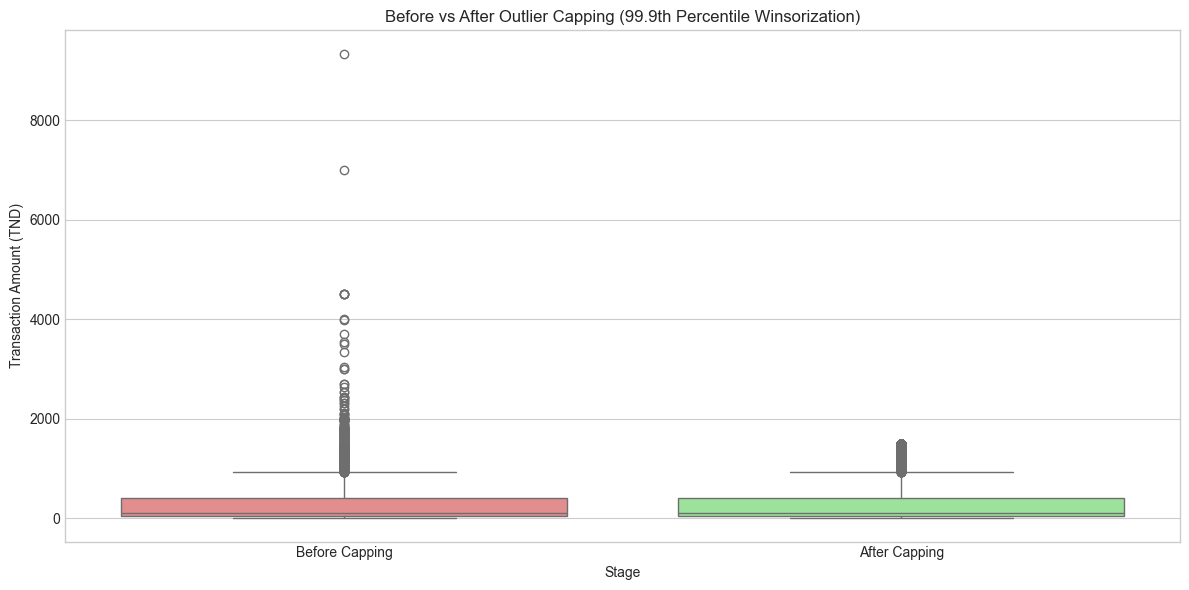

In [65]:
print("="*50)
print("BOXPLOT - BEFORE vs AFTER OUTLIER CAPPING")
print("="*50)

if amount_col:
    # Create dataframe for comparison
    comparison_df = pd.DataFrame({
        'Before Capping': operations_before_cap[amount_col],
        'After Capping': operations[amount_col + '_capped']
    })
    
    # Melt for seaborn
    melted = comparison_df.melt(var_name='Stage', value_name='Amount')
    
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)
    ax.set_title('Before vs After Outlier Capping (99.9th Percentile Winsorization)')
    ax.set_ylabel('Transaction Amount (TND)')
    
    plt.tight_layout()
    plt.show()

      Dataset  Before   After
0  Operations  375267  345572
1   Merchants   33852    9546
2     Clients    9249    9249


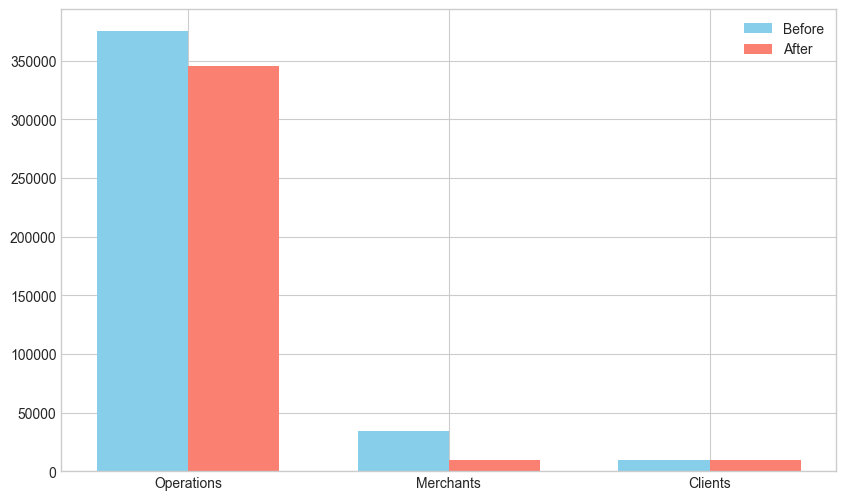

In [66]:
comparison_data = {
    'Dataset': ['Operations', 'Merchants', 'Clients'],
    'Before': [len(operations_raw), len(merchants_raw), len(clients_raw)],
    'After': [len(operations), len(merchants), len(clients)]
}
comparison_df = pd.DataFrame(comparison_data)
print(comparison_df)

fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(comparison_df))
width = 0.35
ax.bar([i - width/2 for i in x], comparison_df['Before'], width, label='Before', color='skyblue')
ax.bar([i + width/2 for i in x], comparison_df['After'], width, label='After', color='salmon')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Dataset'])
ax.legend()
plt.show()

BOXPLOT - BEFORE OUTLIER CAPPING


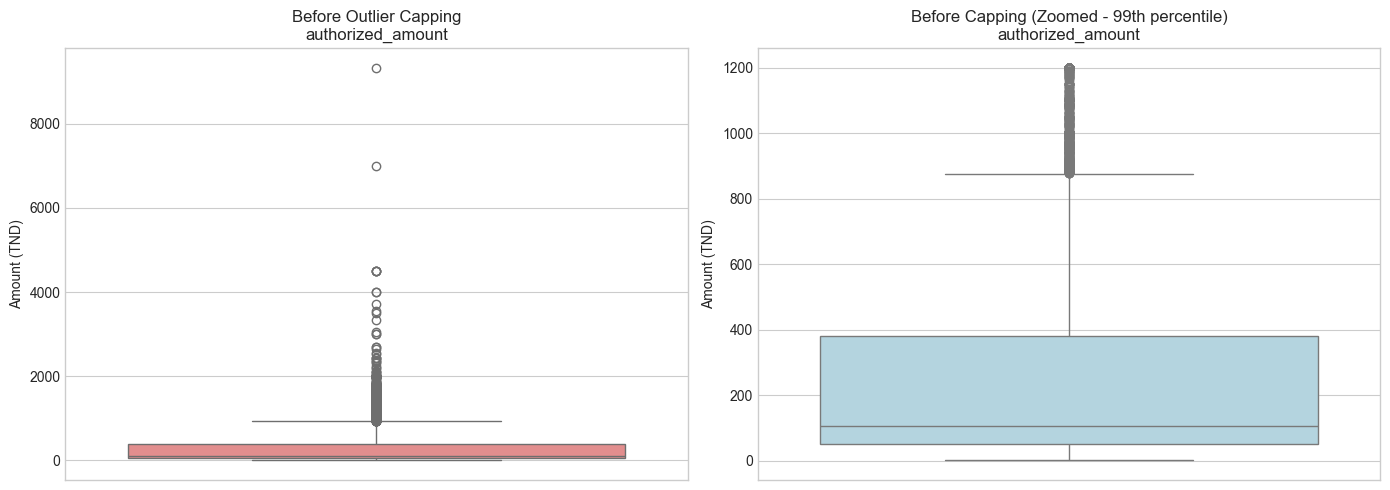

Max value before capping: 9333.00
99th percentile: 1200.00


In [67]:
print("="*50)
print("BOXPLOT - BEFORE OUTLIER CAPPING")
print("="*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1: Before capping (all values)
sns.boxplot(y=operations_before_cap[amount_col], ax=axes[0], color='lightcoral')
axes[0].set_title(f'Before Outlier Capping\n{amount_col}')
axes[0].set_ylabel('Amount (TND)')

# Boxplot 2: Zoomed to see better (without extreme outliers)
filtered = operations_before_cap[operations_before_cap[amount_col] <= operations_before_cap[amount_col].quantile(0.99)]
sns.boxplot(y=filtered[amount_col], ax=axes[1], color='lightblue')
axes[1].set_title(f'Before Capping (Zoomed - 99th percentile)\n{amount_col}')
axes[1].set_ylabel('Amount (TND)')

plt.tight_layout()
plt.show()

print(f"Max value before capping: {operations_before_cap[amount_col].max():.2f}")
print(f"99th percentile: {operations_before_cap[amount_col].quantile(0.99):.2f}")

BOXPLOT - BEFORE vs AFTER OUTLIER CAPPING


C:\Users\merie\AppData\Local\Temp\ipykernel_10628\828196619.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)


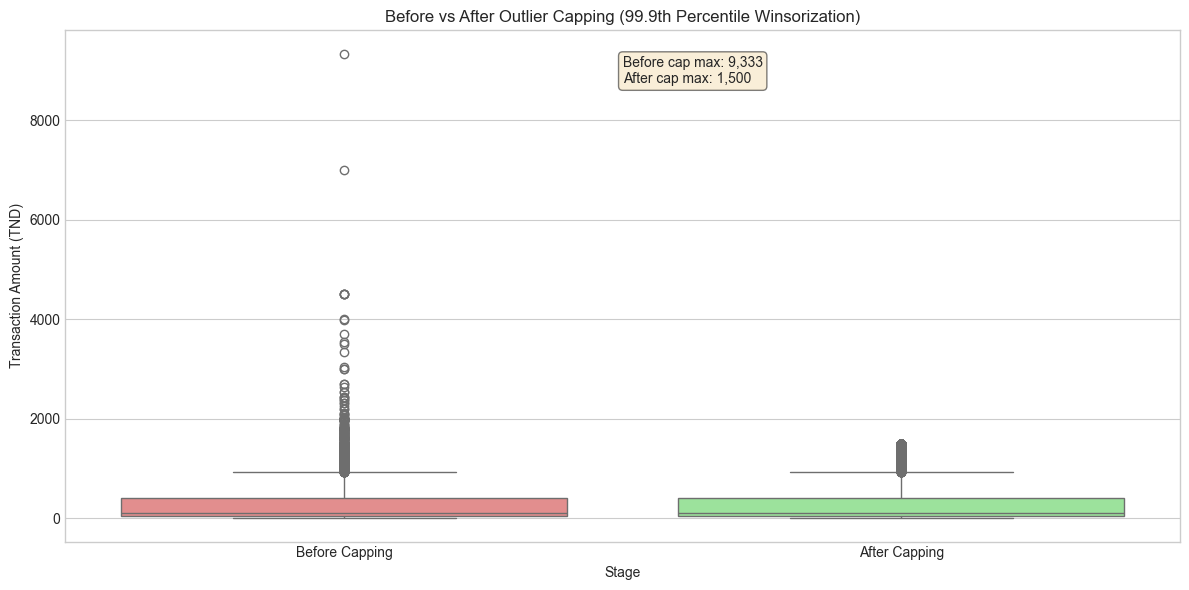

In [68]:
print("="*50)
print("BOXPLOT - BEFORE vs AFTER OUTLIER CAPPING")
print("="*50)

# Create a combined dataframe for comparison
import numpy as np
comparison_df = pd.DataFrame({
    'Before Capping': operations_before_cap[amount_col],
    'After Capping': operations[amount_col + '_capped'] if amount_col + '_capped' in operations.columns else operations[amount_col]
})

# Melt for seaborn
melted = comparison_df.melt(var_name='Stage', value_name='Amount')

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)
ax.set_title('Before vs After Outlier Capping (99.9th Percentile Winsorization)')
ax.set_ylabel('Transaction Amount (TND)')

# Add text with statistics
stats_text = f"Before cap max: {operations_before_cap[amount_col].max():,.0f}\nAfter cap max: {operations[amount_col + '_capped'].max():,.0f}"
ax.text(0.5, 0.95, stats_text, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

HISTOGRAM - TRANSACTION AMOUNT DISTRIBUTION


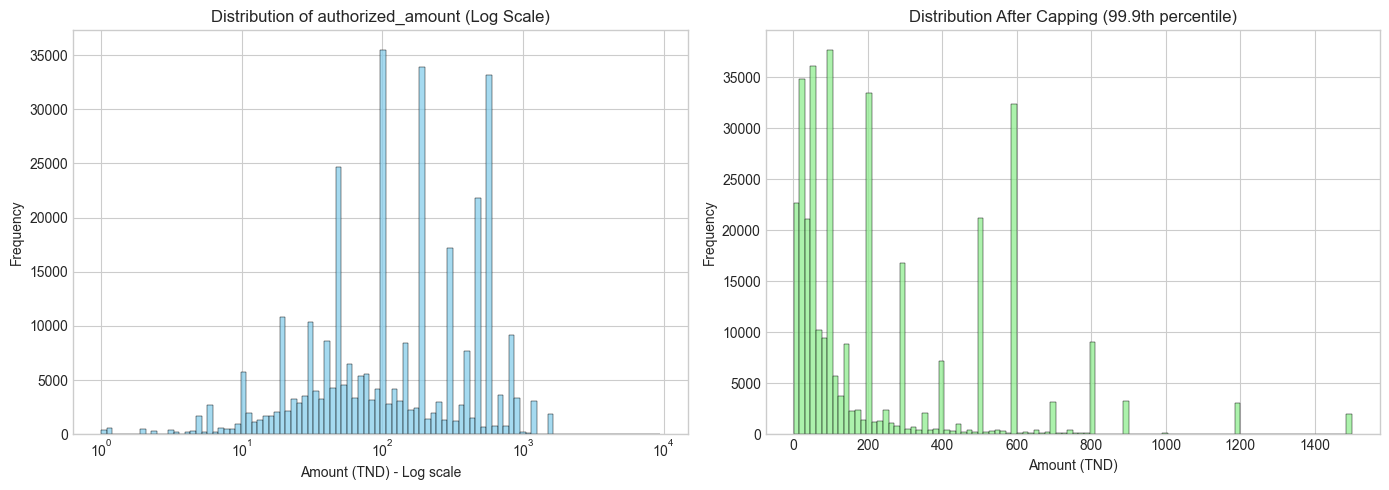

In [69]:
print("="*50)
print("HISTOGRAM - TRANSACTION AMOUNT DISTRIBUTION")
print("="*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: All values (log scale to see distribution)
sns.histplot(operations_before_cap[amount_col], bins=100, ax=axes[0], color='skyblue', log_scale=True)
axes[0].set_title(f'Distribution of {amount_col} (Log Scale)')
axes[0].set_xlabel('Amount (TND) - Log scale')
axes[0].set_ylabel('Frequency')

# Histogram 2: After capping
sns.histplot(operations[amount_col + '_capped'], bins=100, ax=axes[1], color='lightgreen')
axes[1].set_title(f'Distribution After Capping (99.9th percentile)')
axes[1].set_xlabel('Amount (TND)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [70]:
# After loading raw clients, save a copy for age comparison
clients_before_age = clients.copy()
print("✅ clients_before_age saved for age distribution comparison")
print(f"Clients shape before any cleaning: {clients_before_age.shape}")

✅ clients_before_age saved for age distribution comparison
Clients shape before any cleaning: (9249, 1)


AGE DISTRIBUTION - CLIENTS


C:\Users\merie\AppData\Local\Temp\ipykernel_10628\777336394.py:27: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


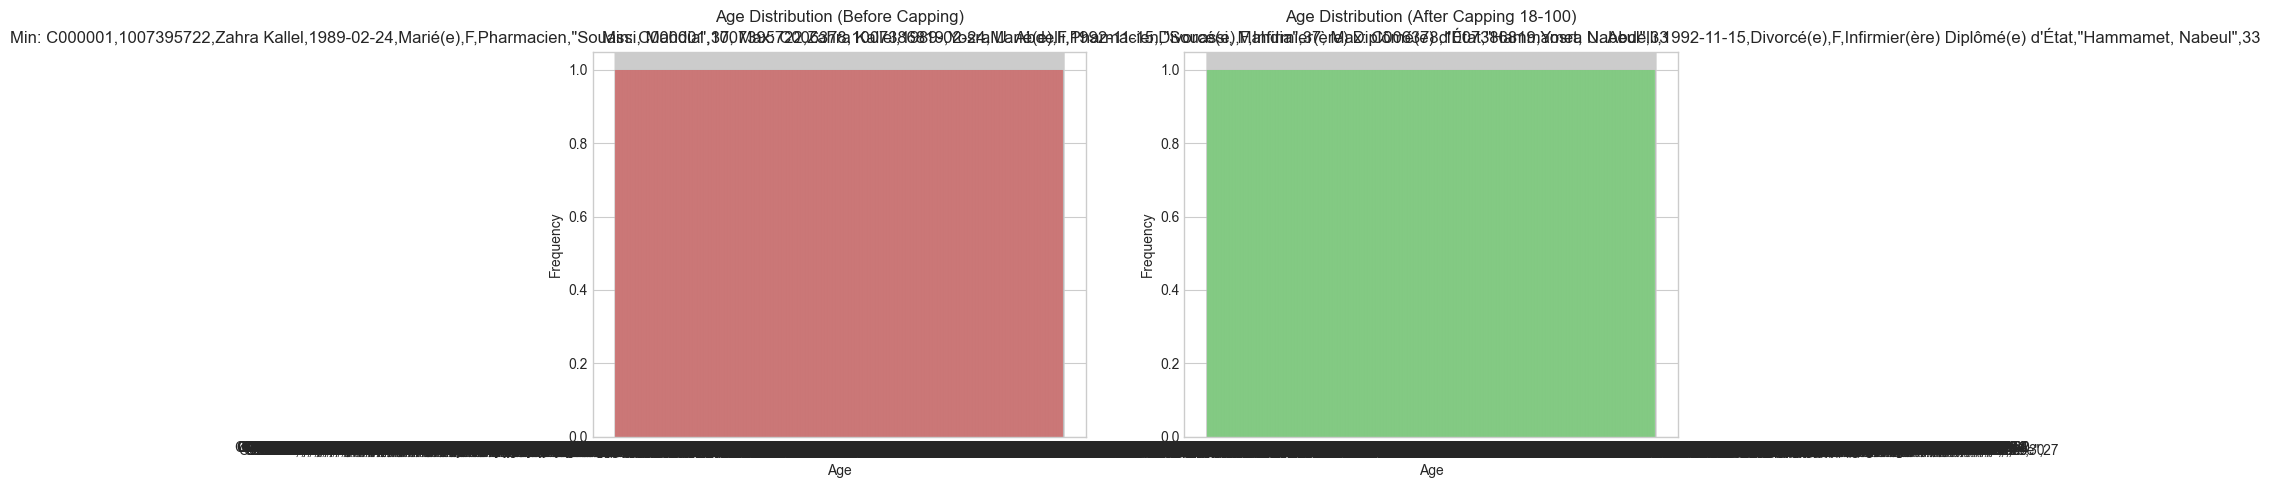

Age before capping - Min: C000001,1007395722,Zahra Kallel,1989-02-24,Marié(e),F,Pharmacien,"Souassi, Mahdia",37, Max: C006378,1007386819,Yosra U. Abdelli,1992-11-15,Divorcé(e),F,Infirmier(ère) Diplômé(e) d'État,"Hammamet, Nabeul",33
Age after capping - Min: C000001,1007395722,Zahra Kallel,1989-02-24,Marié(e),F,Pharmacien,"Souassi, Mahdia",37, Max: C006378,1007386819,Yosra U. Abdelli,1992-11-15,Divorcé(e),F,Infirmier(ère) Diplômé(e) d'État,"Hammamet, Nabeul",33


In [71]:
print("="*50)
print("AGE DISTRIBUTION - CLIENTS")
print("="*50)

# Find age column
age_col = None
for col in clients.columns:
    if 'age' in col.lower():
        age_col = col
        break

if age_col:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Before capping
    sns.histplot(clients_before_age[age_col], bins=30, ax=axes[0], color='lightcoral')
    axes[0].set_title(f'Age Distribution (Before Capping)\nMin: {clients_before_age[age_col].min()}, Max: {clients_before_age[age_col].max()}')
    axes[0].set_xlabel('Age')
    axes[0].set_ylabel('Frequency')
    
    # After capping (between 18 and 100)
    sns.histplot(clients[age_col], bins=30, ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Age Distribution (After Capping 18-100)\nMin: {clients[age_col].min()}, Max: {clients[age_col].max()}')
    axes[1].set_xlabel('Age')
    axes[1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Age before capping - Min: {clients_before_age[age_col].min()}, Max: {clients_before_age[age_col].max()}")
    print(f"Age after capping - Min: {clients[age_col].min()}, Max: {clients[age_col].max()}")
else:
    print("Age column not found. If you have date_of_birth, calculate age first.")

MISSING VALUES HEATMAP - BEFORE vs AFTER


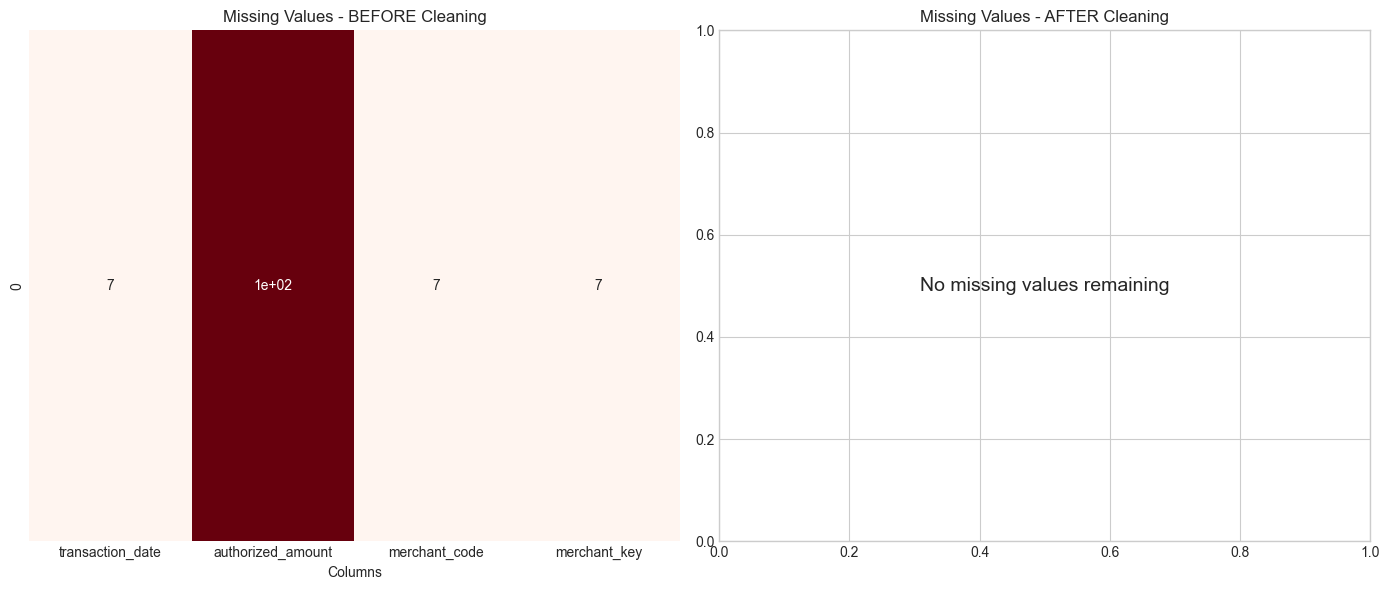

In [72]:
print("="*50)
print("MISSING VALUES HEATMAP - BEFORE vs AFTER")
print("="*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Before cleaning (using raw data)
missing_before = operations_raw.isnull().sum()
missing_before = missing_before[missing_before > 0]
if not missing_before.empty:
    missing_before_df = pd.DataFrame(missing_before).T
    sns.heatmap(missing_before_df, annot=True, cmap='Reds', cbar=False, ax=axes[0])
    axes[0].set_title('Missing Values - BEFORE Cleaning')
    axes[0].set_xlabel('Columns')
    axes[0].set_ylabel('')

# After cleaning
missing_after = operations.isnull().sum()
missing_after = missing_after[missing_after > 0]
if not missing_after.empty:
    missing_after_df = pd.DataFrame(missing_after).T
    sns.heatmap(missing_after_df, annot=True, cmap='Greens', cbar=False, ax=axes[1])
    axes[1].set_title('Missing Values - AFTER Cleaning')
    axes[1].set_xlabel('Columns')
    axes[1].set_ylabel('')
else:
    axes[1].text(0.5, 0.5, 'No missing values remaining', ha='center', va='center', fontsize=14)
    axes[1].set_title('Missing Values - AFTER Cleaning')

plt.tight_layout()
plt.show()

In [73]:
print("="*50)
print("SUMMARY STATISTICS - BEFORE vs AFTER")
print("="*50)

if amount_col:
    print(f"\n{amount_col.upper()} - Summary Statistics:")
    print("-" * 50)
    
    summary_df = pd.DataFrame({
        'Statistic': ['Mean', 'Median', 'Std Dev', 'Min', 'Max', '99.9th Percentile'],
        'Before': [
            f"{operations_before_cap[amount_col].mean():.2f}",
            f"{operations_before_cap[amount_col].median():.2f}",
            f"{operations_before_cap[amount_col].std():.2f}",
            f"{operations_before_cap[amount_col].min():.2f}",
            f"{operations_before_cap[amount_col].max():.2f}",
            f"{operations_before_cap[amount_col].quantile(0.999):.2f}"
        ],
        'After': [
            f"{operations[amount_col + '_capped'].mean():.2f}",
            f"{operations[amount_col + '_capped'].median():.2f}",
            f"{operations[amount_col + '_capped'].std():.2f}",
            f"{operations[amount_col + '_capped'].min():.2f}",
            f"{operations[amount_col + '_capped'].max():.2f}",
            "N/A (capped)"
        ]
    })
    
    print(summary_df.to_string(index=False))

SUMMARY STATISTICS - BEFORE vs AFTER

AUTHORIZED_AMOUNT - Summary Statistics:
--------------------------------------------------
        Statistic  Before        After
             Mean  240.86       240.61
           Median  109.41       109.41
          Std Dev  267.77       265.58
              Min    1.00         1.00
              Max 9333.00      1500.00
99.9th Percentile 1500.00 N/A (capped)
